In [11]:
from typing import TypedDict, Annotated
from langgraph.graph import START, END, StateGraph
from langchain_openai import ChatOpenAI
from langgraph.checkpoint.memory import MemorySaver
from langchain_core.messages import BaseMessage, HumanMessage

In [12]:
from langgraph.graph.message import add_messages

In [13]:
from dotenv import load_dotenv
load_dotenv()

True

In [14]:
import os
model = ChatOpenAI(
  model_name= 'gpt-4o',
  api_key = os.environ.get('OPENAI_API_KEY')
)

In [15]:
class StateClass(TypedDict):
  messages : Annotated[list[BaseMessage], add_messages]


In [16]:


def nodeState(state: StateClass) -> StateClass:
  message = state['messages']
  response = model.invoke(message)
  return{
    'messages': [response]
  }

In [17]:
checkpointer = MemorySaver()
graph = StateGraph(StateClass)

graph.add_node('nodeState',nodeState)
graph.add_edge(START, 'nodeState')
graph.add_edge('nodeState',END)

workflow = graph.compile(checkpointer=checkpointer)

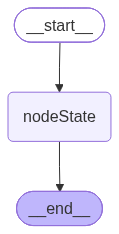

In [18]:
workflow

In [19]:

initial = {
    "messages": [HumanMessage(content="What is the capital of India?")]
}

workflow.invoke(initial)

ValueError: Checkpointer requires one or more of the following 'configurable' keys: thread_id, checkpoint_ns, checkpoint_id

In [ ]:
workflow.invoke(initial)["messages"][-1].content

'The capital of India is New Delhi.'

In [20]:
thread_id = '1'
while True:
  resp = input('Enter your question: ')

  print('User:',resp)

  if resp.strip().lower() in ['quit','exit']:
    print('-----------------------------')
    print('Breaked the loop sucessfully')
    break

  config = {'configurable': {'thread_id': thread_id}}
  
  initial = {
    "messages": [HumanMessage(content=resp)]
  }
  
  generate = workflow.invoke(initial,config=config)
  print('AI: ',generate["messages"][-1].content)

User: what is the capital of pakistan
AI:  The capital of Pakistan is Islamabad.
User: my name is ahrar
AI:  Nice to meet you, Ahrar! How can I assist you today?
User: add me two numbers 100 and 20
AI:  The sum of 100 and 20 is 120.
User: save the sum answer in total 
AI:  I'm unable to save data or persist information, but I can keep track of it within our current conversation. Right now, "total" is 120. If you have any more calculations or questions, feel free to ask!
User: what happens if we subtract 30 from the above total
AI:  If you subtract 30 from the total of 120, the result would be 90.
User: exit
-----------------------------
Breaked the loop sucessfully


In [21]:
workflow.get_state(config=config)

StateSnapshot(values={'messages': [HumanMessage(content='what is the capital of pakistan', additional_kwargs={}, response_metadata={}, id='5a326329-fdfe-4263-aeea-e4b6bbec35dd'), AIMessage(content='The capital of Pakistan is Islamabad.', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 7, 'prompt_tokens': 13, 'total_tokens': 20, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-4o-2024-08-06', 'system_fingerprint': 'fp_2a68371a58', 'id': 'chatcmpl-EZfZxGvUa9dc1buv1iPLbgiaUZrce', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a145a8-3c92-7cb0-9653-26e5b7be7d4b-0', tool_calls=[], invalid_tool_calls=[], usage_metadata=